¿Cuál es la linea base y cuál es su incertidumbre?
¿Usar bootstrap por conglomerados para estimar nuevos intervalos de confianza para diferentes grupos como: tipo de vehículo, distancia a recorrer, tiempo para hacer una entrega?
¿Qué periodo cubre la línea base, por qué ese, y en qué cortes (ruta, producto, proveedor, mes) se reporta?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from pathlib import Path

DS_FILE_ADRESS = Path()
DATA_DIR = DS_FILE_ADRESS/'data'/'plata'
DATA_ADRESS = DATA_DIR/'viajes_foraneos_oro.csv'

In [3]:
df = pd.read_csv(DATA_ADRESS, sep=',')
portacintas = df[df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|COIL', case=False, na=False)]
print("Valores únicos en FAMILIA_CAMION_DESC para portacintas:")
print(portacintas['FAMILIA_CAMION_DESC'].value_counts())
print("\nValores únicos en Tipo Camión para portacintas:")
print(portacintas['Tipo Camión'].value_counts())

Valores únicos en FAMILIA_CAMION_DESC para portacintas:
FAMILIA_CAMION_DESC
PLATAFORMA 3 EJES NEUMATICA BIG COIL             3691
PLATAFORMA 3 EJES NEUMATICA BASES PORTACINTAS    1967
Name: count, dtype: int64

Valores únicos en Tipo Camión para portacintas:
Tipo Camión
Plataforma 3 ejes Neumática BIG COIL             3691
Plataforma 3 ejes Neumática Bases Portacintas    1967
Name: count, dtype: int64


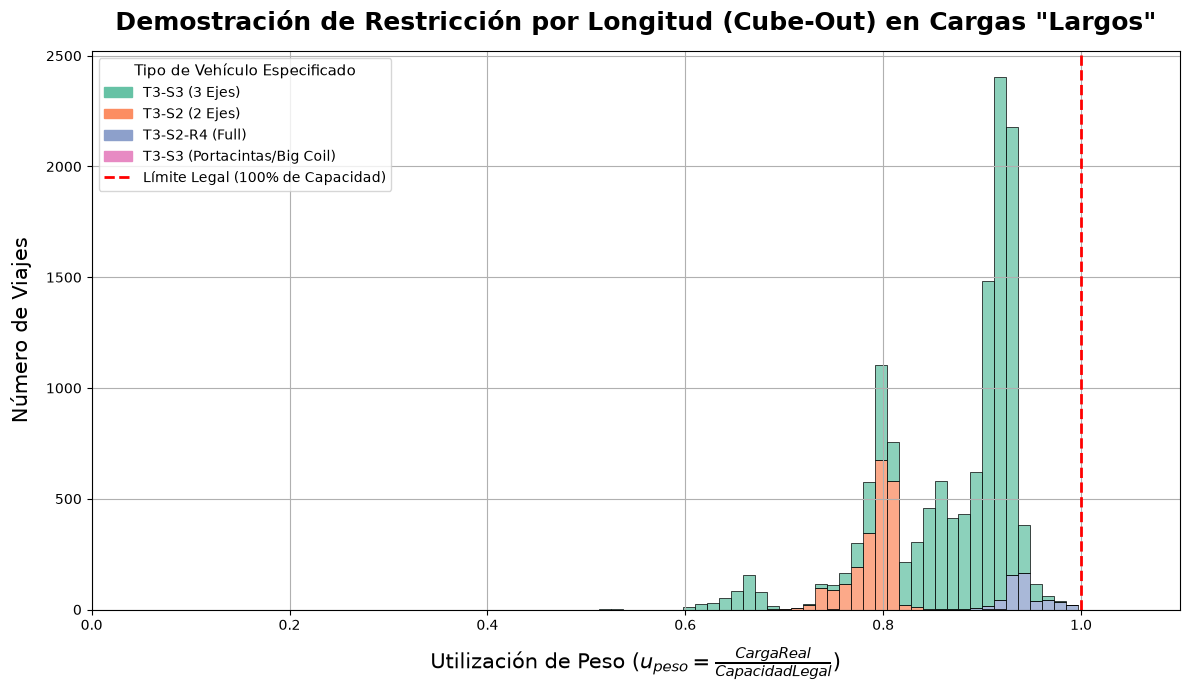

In [4]:
if 'GRUPO_PLANTA_ORIGEN' not in df.columns:
    np.random.seed(42)
    df['GRUPO_PLANTA_ORIGEN'] = np.random.choice(['Largos', 'Revestidos', 'Bodega', 'CeSer'], size=len(df), p=[0.3, 0.4, 0.2, 0.1])

# DIFERENCIAR PORTACINTAS / BIG COIL
# Primero asignamos la nomenclatura base que ya teníamos
df['Programado_kg'] = df['Programado (Peso)'] * 1000
LIMITE_2_EJES = 32000; LIMITE_3_EJES = 38500; LIMITE_FULL = 46000

condiciones_base = [
    (df['Programado_kg'] > LIMITE_3_EJES),
    (df['Programado_kg'] > LIMITE_2_EJES) & (df['Programado_kg'] <= LIMITE_3_EJES),
    (df['Programado_kg'] <= LIMITE_2_EJES) & (df['FAMILIA_CAMION_DESC'].astype(str).str.contains('3 EJES', case=False, na=False)),
    (df['Programado_kg'] <= LIMITE_2_EJES) & (df['FAMILIA_CAMION_DESC'].astype(str).str.contains('2 EJES', case=False, na=False))
]
nomenclaturas_base = ['T3-S2-R4 (Full)', 'T3-S3 (3 Ejes)', 'T3-S3 (3 Ejes)', 'T3-S2 (2 Ejes)']
df['Nomenclatura_Base'] = np.select(condiciones_base, nomenclaturas_base, default='T3-S2 (2 Ejes)')

capacidades = [LIMITE_FULL, LIMITE_3_EJES, LIMITE_3_EJES, LIMITE_2_EJES]
df['Capacidad_Max_kg'] = np.select(condiciones_base, capacidades, default=LIMITE_2_EJES)

# Separar los Portacintas de los 3 Ejes genéricos
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Nomenclatura_Final'] = np.where(mascara_portacintas, 'T3-S3 (Portacintas/Big Coil)', df['Nomenclatura_Base'])

# CALCULAR UTILIZACIÓN DE PESO
df['u_peso'] = df['Porcentaje_Utilizacion_Real']/100

# FILTRAR Y GRAFICAR "LARGOS"
df_largos = df[df['GRUPO_PLANTA_ORIGEN'] == 'Largos'].copy()

orden_camiones = df_largos['Nomenclatura_Final'].unique()
paleta_colores = sns.color_palette('Set2', n_colors=len(orden_camiones))

# Generar el gráfico forzando el orden de los colores (hue_order)
plt.figure(figsize=(12, 7))
ax = sns.histplot(
    data=df_largos, 
    x='u_peso', 
    hue='Nomenclatura_Final',
    hue_order=orden_camiones, # Forzamos el orden
    multiple="stack", 
    bins=40, 
    palette=paleta_colores,
    edgecolor='black',
    linewidth=0.5
)

# Dibujar la línea de restricción dura
linea_limite = plt.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Límite Legal (100% de Capacidad)')

manejadores_leyenda = []

for i, nombre_camion in enumerate(orden_camiones):
    parche = mpatches.Patch(color=paleta_colores[i], label=nombre_camion)
    manejadores_leyenda.append(parche)

manejadores_leyenda.append(linea_limite)

plt.legend(
    handles=manejadores_leyenda, 
    title='Tipo de Vehículo Especificado', 
    loc='upper left',
    fontsize='10', 
    title_fontsize='11',
    frameon=True
)

plt.title('Demostración de Restricción por Longitud (Cube-Out) en Cargas "Largos"', fontsize=18, fontweight='bold', pad=15)
plt.xlabel('Utilización de Peso ($u_{peso} = \\frac{Carga Real}{Capacidad Legal}$)', fontsize=15, labelpad=10)
plt.ylabel('Número de Viajes', fontsize=15, labelpad=10)
plt.xlim(0, 1.1)

plt.tight_layout()
plt.grid()
plt.show()

In [5]:
df['u_peso'] = df['Porcentaje_Utilizacion_Real'] / 100

# Filtrar exclusivamente las cargas donde la dimensión que amarra asume ser el volumen/largo
df_largos = df[df['GRUPO_PLANTA_ORIGEN'] == 'Largos'].copy()

df['u_volumen'] = np.where(df['GRUPO_PLANTA_ORIGEN'] == 'Largos', 1.0, df['u_peso'] * 0.85)

# Utilización Efectiva (u_i = max(q_ik / c_ik))
df['u_efectiva'] = df[['u_peso', 'u_volumen']].max(axis=1)

# Identificar la Dimensión que Amarra (k*_i = argmax(q_ik / c_ik))
df['Dimension_Amarra'] = np.where(df['u_volumen'] >= df['u_peso'], 'Volumen/Largo', 'Peso Legal')

# Mostrar las frecuencias de amarre
print("Frecuencia de la dimensión que amarra por tipo de camión:")
display(pd.crosstab(df['Nomenclatura_Inferida'], df['Dimension_Amarra'], margins=True))

Frecuencia de la dimensión que amarra por tipo de camión:


Dimension_Amarra,Peso Legal,Volumen/Largo,All
Nomenclatura_Inferida,,,
Cama Baja Doble Piso,167,0,167
Heavy,34,0,34
Plataforma larga 48 pies,343,0,343
Plataforma larga 53 pies,2,0,2
T3-S2 (2 Ejes),6669,2146,8815
T3-S2-R4 (Full),287,528,815
T3-S3 (3 Ejes),26972,10633,37605
T3-S3 (Portacintas/Big Coil),5652,5,5657
Torton,1671,0,1671


Estadísticas de utilización (u_peso) para cargas amarradas por Báscula:


,count,mean,median,min,max,std
Nomenclatura_Inferida,,,,,,
Cama Baja Doble Piso,167,0.830,0.835,0.567,0.975,0.076
Plataforma larga 48 pies,343,0.920,0.920,0.473,1.191,0.082
Plataforma larga 53 pies,2,1.024,1.024,1.007,1.041,0.024
T3-S2 (2 Ejes),6669,0.752,0.765,0.091,0.996,0.078
T3-S2-R4 (Full),287,0.754,0.753,0.747,0.775,0.005
T3-S3 (3 Ejes),26972,0.806,0.831,0.278,0.999,0.124
T3-S3 (Portacintas/Big Coil),5652,0.730,0.701,0.208,0.997,0.091
Torton,1671,0.744,0.769,0.329,0.873,0.087
Tortoneta,249,0.766,0.771,0.585,0.896,0.066


/var/folders/2g/lzkw6wx57k5fk4j7x71sq2sr0000gn/T/ipykernel_4078/2349821940.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


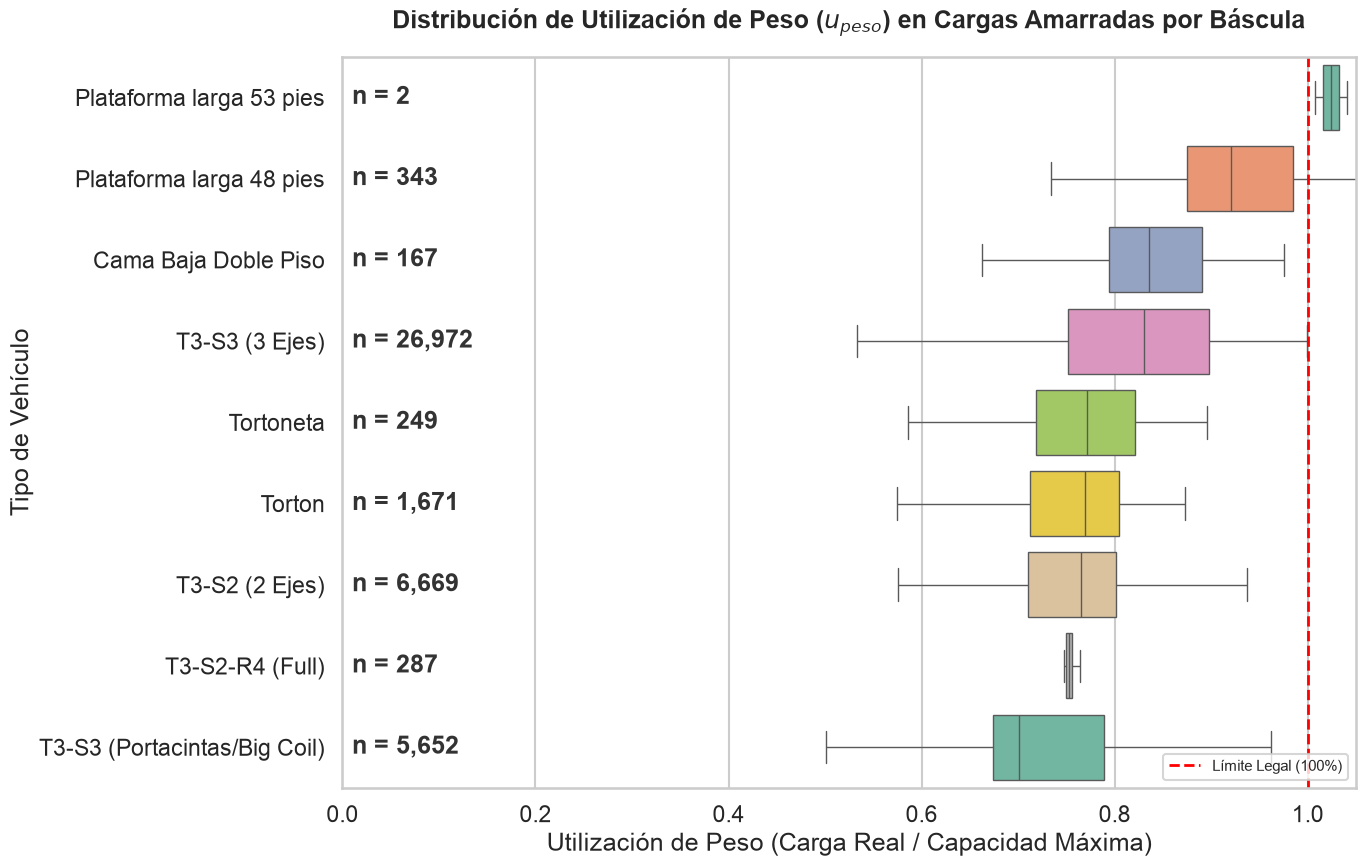

In [6]:
df['Dimension_Amarra'] = np.where(df['GRUPO_PLANTA_ORIGEN'] == 'Largos', 'Volumen/Largo', 'Peso Legal')
df_peso = df[(df['Dimension_Amarra'] == 'Peso Legal') & (df['Nomenclatura_Inferida'] != 'Heavy')].copy()

# Calcular y mostrar las estadísticas descriptivas
stats = df_peso.groupby('Nomenclatura_Inferida')['u_peso'].agg(
    count='count', mean='mean', median='median', min='min', max='max', std='std'
).round(3)

print("Estadísticas de utilización (u_peso) para cargas amarradas por Báscula:")
display(stats)

# Generar el Boxplot
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid", context="talk")

# Ordenar las cajas de mayor a menor mediana
orden_cajas = df_peso.groupby('Nomenclatura_Inferida')['u_peso'].median().sort_values(ascending=False).index

ax = sns.boxplot(
    data=df_peso, 
    y='Nomenclatura_Inferida', 
    x='u_peso', 
    order=orden_cajas,
    palette='Set2',
    showfliers=False # Oculta los diamantes de outliers para limpiar la vista
)

# Añadir las cantidades (n) de la tabla directamente al inicio de cada caja
for i, camion in enumerate(orden_cajas):
    cantidad = stats.loc[camion, 'count']
    ax.text(0.01, i, f'n = {int(cantidad):,}', verticalalignment='center', size=18, weight='bold', color='#333333')

# Formato y etiquetas
plt.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Límite Legal (100%)')
plt.title('Distribución de Utilización de Peso ($u_{peso}$) en Cargas Amarradas por Báscula', pad=20, fontweight='bold')
plt.xlabel('Utilización de Peso (Carga Real / Capacidad Máxima)')
plt.ylabel('Tipo de Vehículo')
plt.legend(loc='lower right', frameon=True, fontsize = 11)
plt.xlim(0, 1.05)

plt.tight_layout()
plt.show()

Nulos en Kilometros_Ruta: 0

Estadísticas de Kilometros_Ruta:
count    55358.000000
mean       693.048467
std        435.022993
min          1.451900
25%        384.876500
50%        666.508100
75%        918.491700
max       4054.364000
Name: Kilometros_Ruta, dtype: float64

Tercil 33%: 475.8 km
Tercil 66%: 796.7 km

Gráfica guardada como distribucion_distancias.png


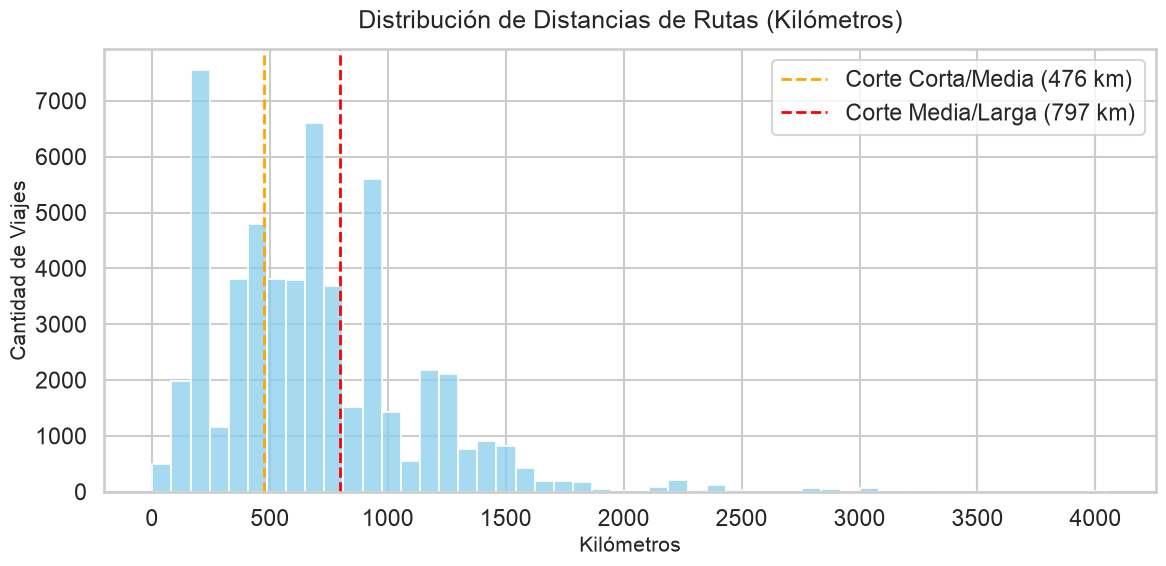

In [7]:
nulos = df['Kilometros_Ruta'].isna().sum()
print(f"Nulos en Kilometros_Ruta: {nulos}")

# Estadísticas descriptivas de la distancia
stats_km = df['Kilometros_Ruta'].describe()
print("\nEstadísticas de Kilometros_Ruta:")
print(stats_km)

# Calcular percentiles para proponer cortes (terciles)
tercil_33 = df['Kilometros_Ruta'].quantile(0.33)
tercil_66 = df['Kilometros_Ruta'].quantile(0.66)
print(f"\nTercil 33%: {tercil_33:.1f} km")
print(f"Tercil 66%: {tercil_66:.1f} km")

# Graficar la distribución
plt.figure(figsize=(12, 6))
sns.histplot(df['Kilometros_Ruta'], bins=50, color='skyblue')
plt.axvline(tercil_33, color='orange', linestyle='--', linewidth=2, label=f'Corte Corta/Media ({tercil_33:.0f} km)')
plt.axvline(tercil_66, color='red', linestyle='--', linewidth=2, label=f'Corte Media/Larga ({tercil_66:.0f} km)')

plt.title('Distribución de Distancias de Rutas (Kilómetros)', fontsize=18, pad=15)
plt.xlabel('Kilómetros', fontsize=15)
plt.ylabel('Cantidad de Viajes', fontsize=15)
plt.legend()
plt.tight_layout()
#plt.savefig('distribucion_distancias.png')
print("\nGráfica guardada como distribucion_distancias.png")

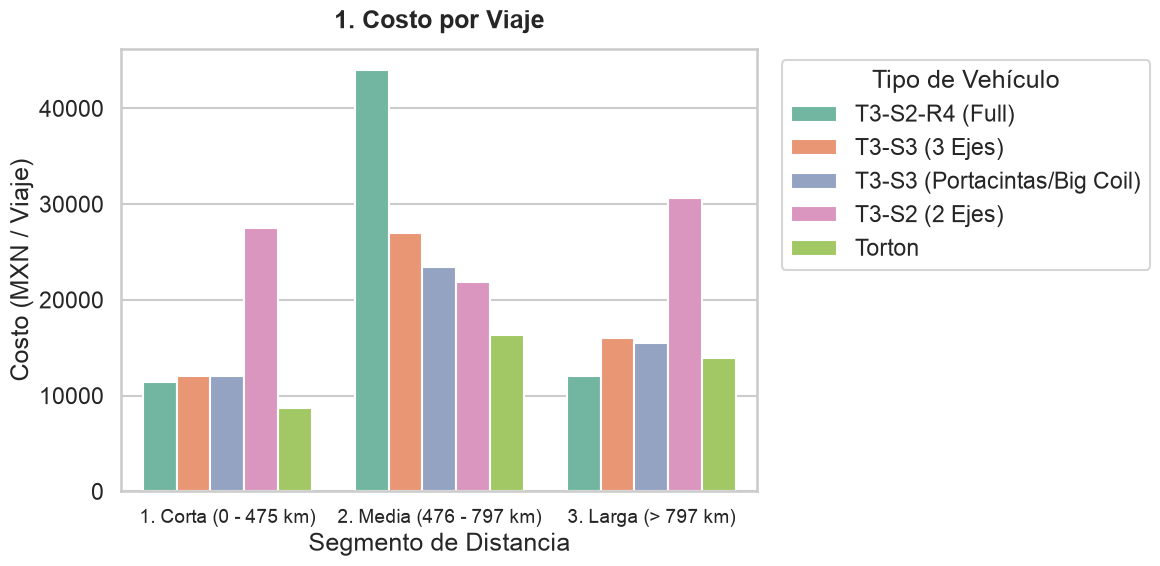

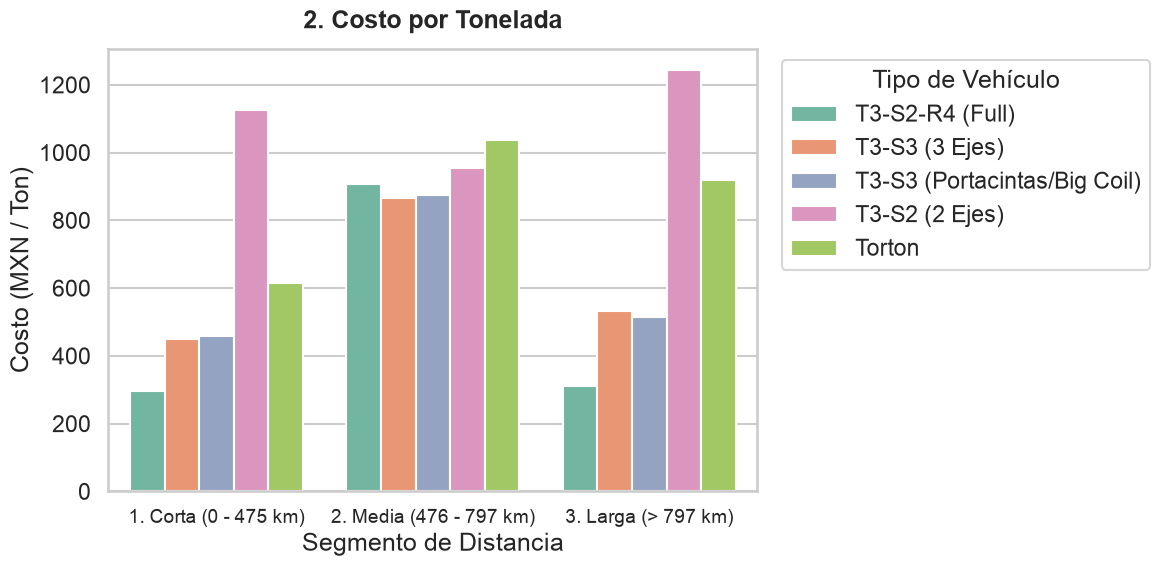

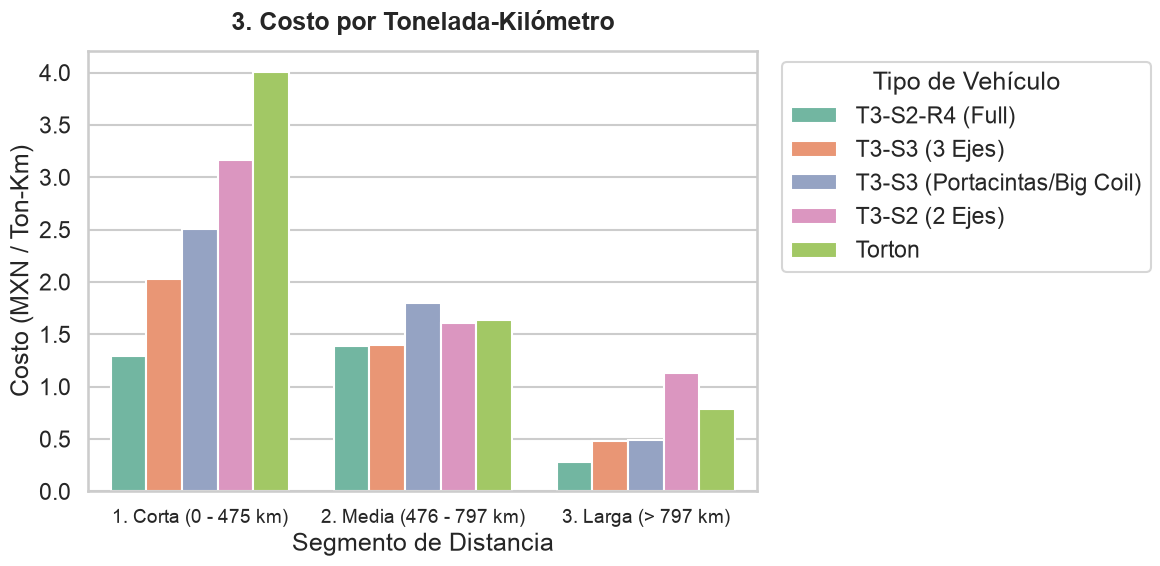

Medianas de costo para rutas LARGAS:
 | Nomenclatura_Final           |   Costo_Viaje |   Costo_Ton_Real |   Costo_Ton_Km |
|:-----------------------------|--------------:|-----------------:|---------------:|
| T3-S2 (2 Ejes)               |         30641 |          1243.51 |           1.13 |
| T3-S2-R4 (Full)              |         12050 |           310.27 |           0.28 |
| T3-S3 (3 Ejes)               |         15966 |           532.01 |           0.48 |
| T3-S3 (Portacintas/Big Coil) |         15462 |           515.29 |           0.5  |
| Torton                       |         13928 |           919.89 |           0.79 |


In [8]:
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Nomenclatura_Final'] = np.where(mascara_portacintas, 'T3-S3 (Portacintas/Big Coil)', df['Nomenclatura_Inferida'])

# Crear categorías de distancia
bins = [0, 475, 797, np.inf]
labels = ['1. Corta (0 - 475 km)', '2. Media (476 - 797 km)', '3. Larga (> 797 km)']
df['Categoria_Distancia'] = pd.cut(df['Kilometros_Ruta'], bins=bins, labels=labels)

# Filtrar vehículos objetivo
vehiculos_objetivo = [
    'T3-S2-R4 (Full)', 
    'T3-S3 (3 Ejes)', 
    'T3-S3 (Portacintas/Big Coil)', 
    'T3-S2 (2 Ejes)', 
    'Torton'
]
df_costos = df[df['Nomenclatura_Final'].isin(vehiculos_objetivo)].copy()
df_costos['Costo_Viaje'] = df_costos['Monto total']

# Configuración visual base
sns.set_theme(style="whitegrid", context="talk")
paleta = sns.color_palette('Set2', n_colors=len(vehiculos_objetivo))

# ==========================================
# GRÁFICO 1: COSTO POR VIAJE
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_costos, x='Categoria_Distancia', y='Costo_Viaje', hue='Nomenclatura_Final', 
    estimator=np.median, palette=paleta, hue_order=vehiculos_objetivo, errorbar=None
)
plt.title('1. Costo por Viaje', fontweight='bold', pad=15)
plt.ylabel('Costo (MXN / Viaje)')
plt.xlabel('Segmento de Distancia')
plt.legend(title='Tipo de Vehículo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(fontsize=14)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 2: COSTO POR TONELADA
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_costos, x='Categoria_Distancia', y='Costo_Ton_Real', hue='Nomenclatura_Final', 
    estimator=np.median, palette=paleta, hue_order=vehiculos_objetivo,errorbar=None
)
plt.title('2. Costo por Tonelada', fontweight='bold', pad=15)
plt.ylabel('Costo (MXN / Ton)')
plt.xlabel('Segmento de Distancia')
plt.legend(title='Tipo de Vehículo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(fontsize=14)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 3: COSTO POR TON-KM
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_costos, x='Categoria_Distancia', y='Costo_Ton_Km', hue='Nomenclatura_Final', 
    estimator=np.median, palette=paleta, hue_order=vehiculos_objetivo,errorbar=None
)
plt.title('3. Costo por Tonelada-Kilómetro', fontweight='bold', pad=15)
plt.ylabel('Costo (MXN / Ton-Km)')
plt.xlabel('Segmento de Distancia')
plt.legend(title='Tipo de Vehículo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(fontsize=14)
plt.tight_layout()
plt.show()

resumen_larga = df_costos[df_costos['Categoria_Distancia'] == '3. Larga (> 797 km)'].groupby('Nomenclatura_Final')[['Costo_Viaje', 'Costo_Ton_Real', 'Costo_Ton_Km']].median().round(2)
print("Medianas de costo para rutas LARGAS:\n", resumen_larga.to_markdown())

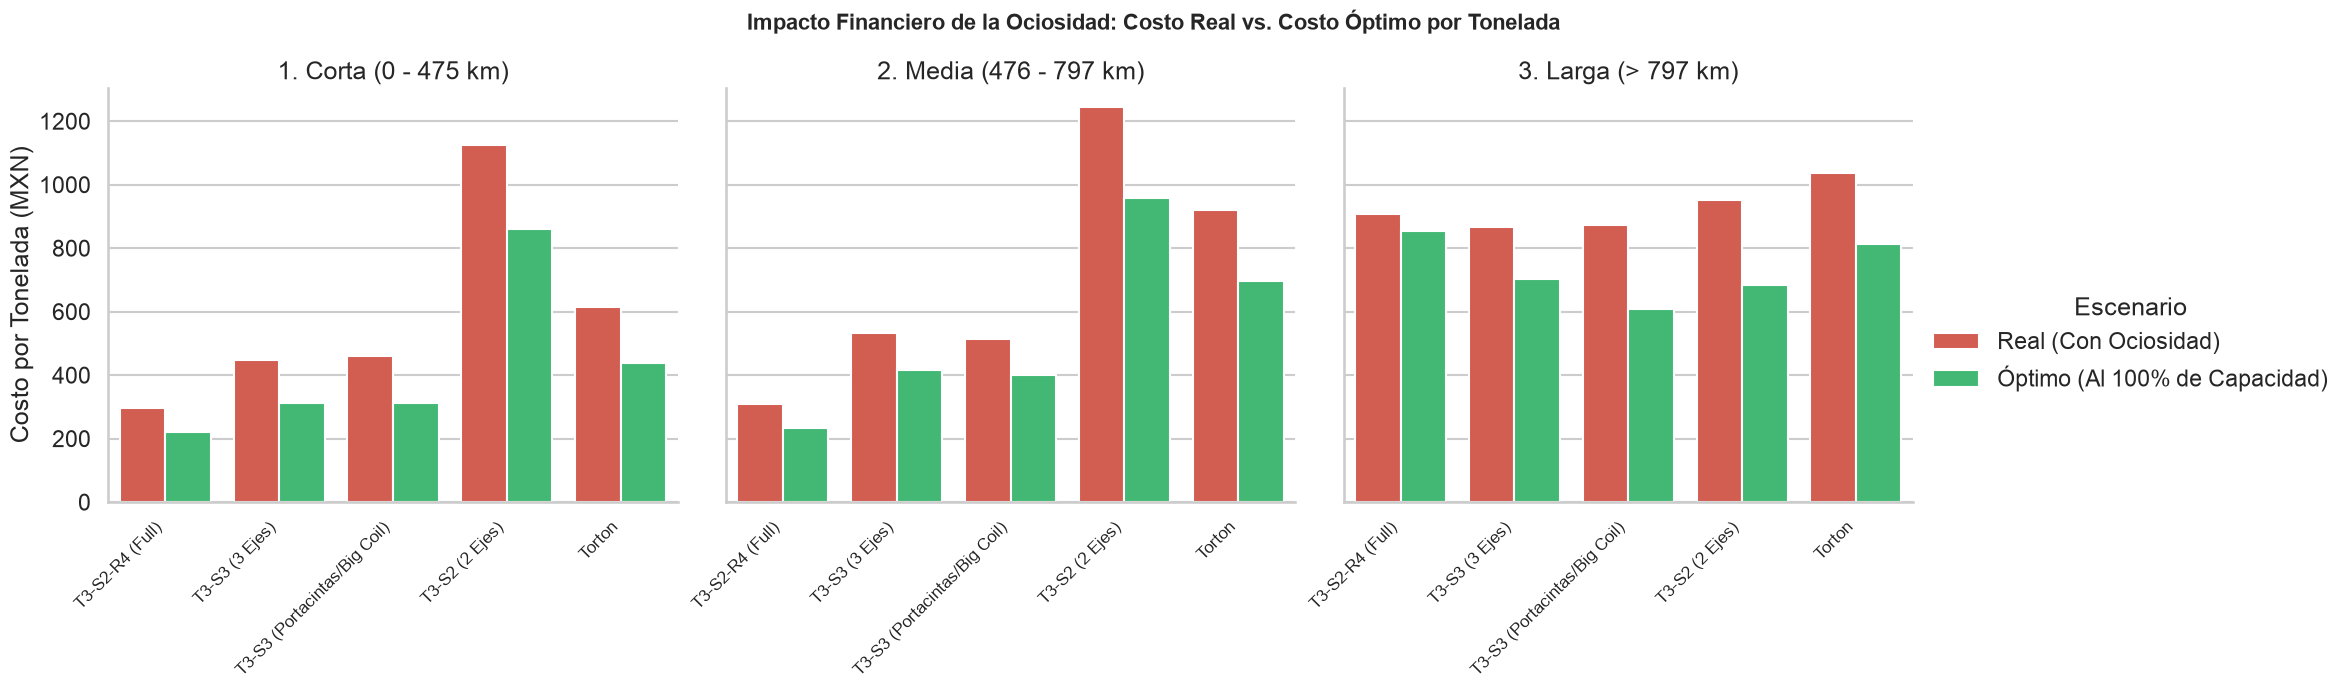

--- AHORRO POTENCIAL EVITABLE POR TIPO DE UNIDAD ---


,Nomenclatura_Final,Sobrecosto (Millones MXN)
2,T3-S3 (3 Ejes),148.76
0,T3-S2 (2 Ejes),53.55
3,T3-S3 (Portacintas/Big Coil),27.86
4,Torton,5.22
1,T3-S2-R4 (Full),2.43


In [9]:
bins = [0, 475, 797, np.inf]
vehiculos_objetivo = ['T3-S2-R4 (Full)', 'T3-S3 (3 Ejes)', 'T3-S3 (Portacintas/Big Coil)', 'T3-S2 (2 Ejes)', 'Torton']
df_obj = df[df['Nomenclatura_Final'].isin(vehiculos_objetivo)].copy()

# 2. Transformación para la visualización (Melt)
df_melt = df_obj.melt(id_vars=['Nomenclatura_Final', 'Categoria_Distancia'], 
                      value_vars=['Costo_Ton_Real', 'Costo_Ton_Optimo'],
                      var_name='Escenario', value_name='Costo_Ton')

df_melt['Escenario'] = df_melt['Escenario'].replace({
    'Costo_Ton_Real': 'Real (Con Ociosidad)', 
    'Costo_Ton_Optimo': 'Óptimo (Al 100% de Capacidad)'
})

# 3. Visualización comparativa
sns.set_theme(style="whitegrid", context="talk")
g = sns.catplot(
    data=df_melt, kind="bar",
    x="Nomenclatura_Final", y="Costo_Ton", hue="Escenario", col="Categoria_Distancia",
    estimator=np.median, errorbar=None, palette=['#e74c3c', '#2ecc71'], 
    height=6, aspect=1.1, sharey=True, order=vehiculos_objetivo
)

g.set_axis_labels("", "Costo por Tonelada (MXN)")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45, ha='right', fontsize=12)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Impacto Financiero de la Ociosidad: Costo Real vs. Costo Óptimo por Tonelada', fontweight='bold', fontsize=16)

plt.show()

# 4. Cálculo del Ahorro Evitable Total
df_obj['Sobrecosto_Por_Viaje'] = df_obj['Sobrecosto_Ton'] * df_obj['Toneladas_Reales']
resumen_ahorro = df_obj.groupby('Nomenclatura_Final')['Sobrecosto_Por_Viaje'].sum().reset_index()
resumen_ahorro['Sobrecosto (Millones MXN)'] = (resumen_ahorro['Sobrecosto_Por_Viaje'] / 1e6).round(2)
resumen_ahorro = resumen_ahorro.sort_values('Sobrecosto (Millones MXN)', ascending=False)

print("--- AHORRO POTENCIAL EVITABLE POR TIPO DE UNIDAD ---")
display(resumen_ahorro[['Nomenclatura_Final', 'Sobrecosto (Millones MXN)']])

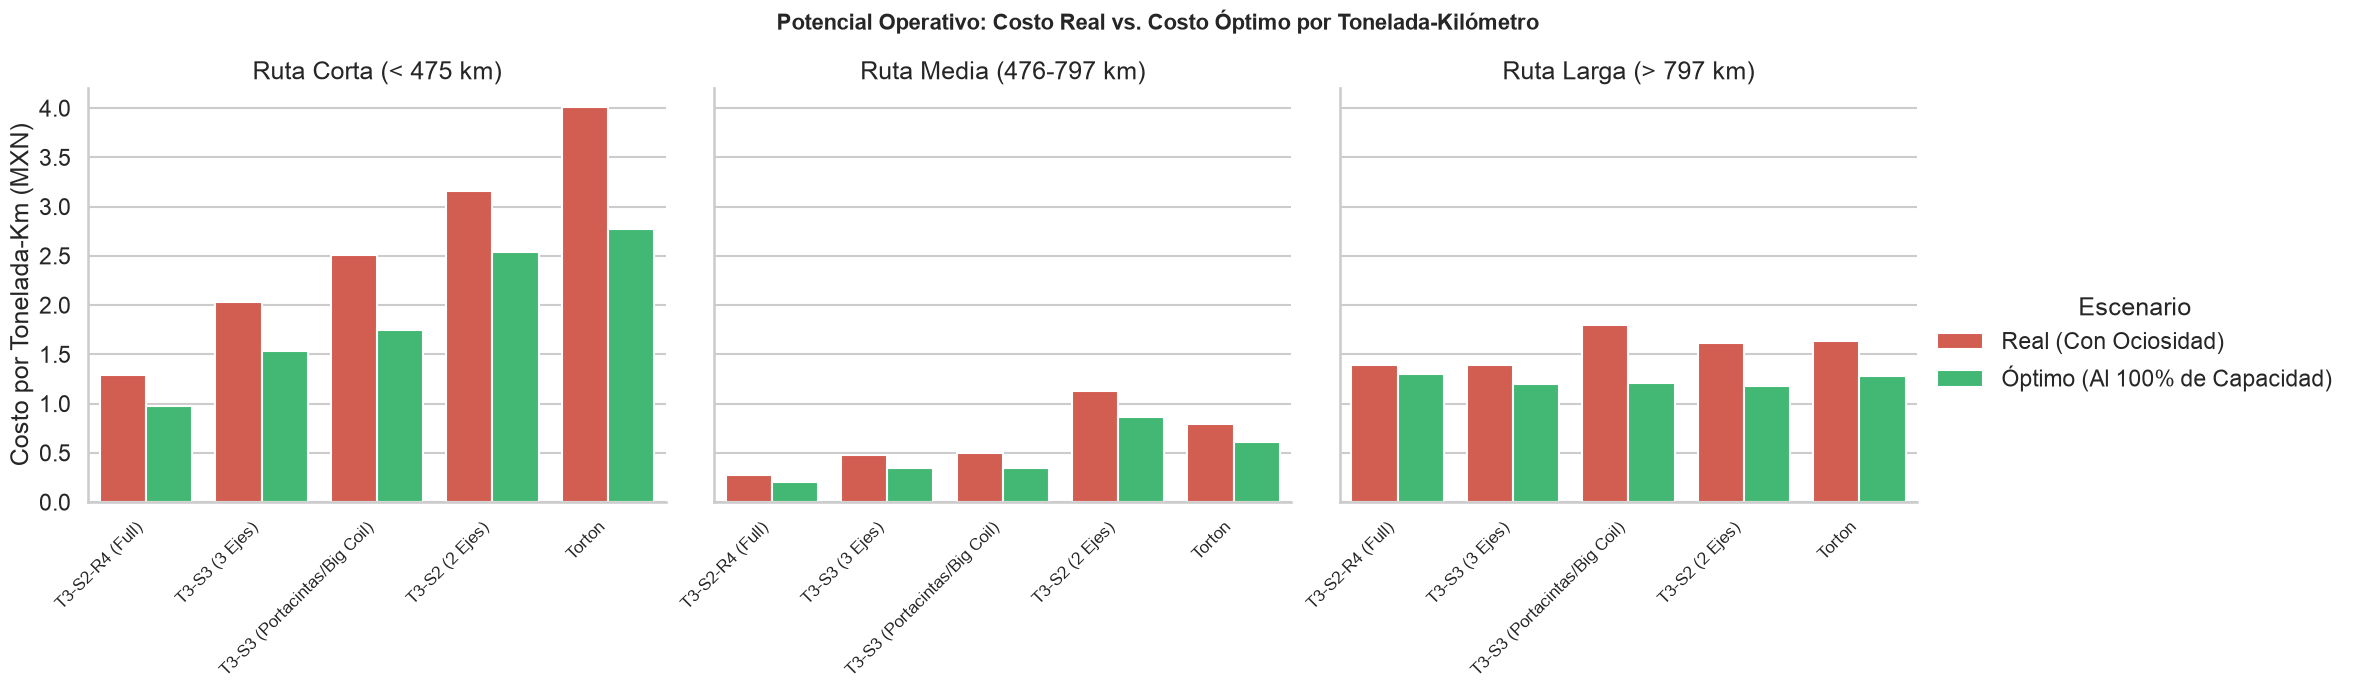

In [10]:
bins = [0, 475, 797, np.inf]
labels = ['Ruta Corta (< 475 km)', 'Ruta Media (476-797 km)', 'Ruta Larga (> 797 km)']
df['Categoria_Distancia'] = pd.cut(df['Kilometros_Ruta'], bins=bins, labels=labels)

vehiculos_objetivo = ['T3-S2-R4 (Full)', 'T3-S3 (3 Ejes)', 'T3-S3 (Portacintas/Big Coil)', 'T3-S2 (2 Ejes)', 'Torton']
df_obj = df[df['Nomenclatura_Final'].isin(vehiculos_objetivo)].copy()

# 2. Calcular el Costo por Ton-Km Óptimo
# (Ton-Km ideal asumiendo que siempre viajan al 100% de la capacidad legal)
df_obj['Tonelada_Kilometro_Optimo'] = df_obj['Toneladas_Maximas'] * df_obj['Kilometros_Ruta']
df_obj['Costo_Ton_Km_Optimo'] = df_obj['Monto total'] / df_obj['Tonelada_Kilometro_Optimo'].replace(0, np.nan)

# 3. Preparar el DataFrame para la visualización de comparación
df_melt_km = df_obj.melt(id_vars=['Nomenclatura_Final', 'Categoria_Distancia'], 
                         value_vars=['Costo_Ton_Km', 'Costo_Ton_Km_Optimo'],
                         var_name='Escenario', value_name='Costo')

df_melt_km['Escenario'] = df_melt_km['Escenario'].replace({
    'Costo_Ton_Km': 'Real (Con Ociosidad)', 
    'Costo_Ton_Km_Optimo': 'Óptimo (Al 100% de Capacidad)'
})

# 4. Generar el Gráfico de Barras Agrupadas
sns.set_theme(style="whitegrid", context="talk")
g = sns.catplot(
    data=df_melt_km, kind="bar",
    x="Nomenclatura_Final", y="Costo", hue="Escenario", col="Categoria_Distancia",
    estimator=np.median, errorbar=None, palette=['#e74c3c', '#2ecc71'], 
    height=6, aspect=1.1, sharey=True, order=vehiculos_objetivo
)

g.set_axis_labels("", "Costo por Tonelada-Km (MXN)")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45, ha='right', fontsize=12)

g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Potencial Operativo: Costo Real vs. Costo Óptimo por Tonelada-Kilómetro', fontweight='bold', fontsize=16)

plt.show()

In [13]:
candidatos_right_sizing = [
    ('Tortoneta', 12000),
    ('Torton', 20000),
    ('T3-S2 (2 Ejes)', 32000),
    ('T3-S3 (3 Ejes)', 38500),
    ('T3-S2-R4 (Full)', 51500)
]

HOLGURA_SEGURIDAD = 0.95

# 3. Fase 1: Viabilidad Física
def aplicar_right_sizing_fisico(row):
    if row['Dimension_Amarra'] != 'Peso Legal' or row['Nomenclatura_Final'] == 'T3-S3 (Portacintas/Big Coil)':
        return row['Nomenclatura_Final']
    
    peso_real = row['Peso Total']
    for vehiculo, capacidad_maxima in candidatos_right_sizing:
        if peso_real <= (capacidad_maxima * HOLGURA_SEGURIDAD):
            return vehiculo
    return row['Nomenclatura_Final']

df['Vehiculo_Fisico'] = df.apply(aplicar_right_sizing_fisico, axis=1)

# 4. Fase 2: Viabilidad Financiera por Distancia
# Generamos un diccionario de referencia con las tarifas medianas por distancia
costos_medios = df.groupby(['Nomenclatura_Final', 'Categoria_Distancia'], observed=False)['Monto total'].median().to_dict()

def aplicar_filtro_financiero(row):
    veh_original = row['Nomenclatura_Final']
    veh_sugerido = row['Vehiculo_Fisico']
    distancia = row['Categoria_Distancia']
    
    if veh_original == veh_sugerido:
        return veh_original
        
    costo_real_pagado = row['Monto total']
    
    # Estimamos cuánto nos cobraría el nuevo vehículo en esa ruta
    clave_esperada = (veh_sugerido, distancia)
    costo_esperado = costos_medios.get(clave_esperada, np.inf)
    
    # Solo cambiamos si el vehículo sugerido es efectivamente más barato
    if costo_esperado >= costo_real_pagado:
        return veh_original
        
    return veh_sugerido

print("Ejecutando motor de optimización financiera...")
df['Vehiculo_Recomendado_Final'] = df.apply(aplicar_filtro_financiero, axis=1)

# 5. Resultados
cambiados_financieros = df[df['Nomenclatura_Final'] != df['Vehiculo_Recomendado_Final']]
print(f"\nViajes consolidados con viabilidad financiera garantizada: {len(cambiados_financieros):,} viajes.")

transicion = pd.crosstab(
    df['Nomenclatura_Final'], 
    df['Vehiculo_Recomendado_Final'], 
    rownames=['Original'], 
    colnames=['Sugerido']
)
print("\nMatriz Logística (Optimizada por Costo/Distancia):")
display(transicion)

Ejecutando motor de optimización financiera...

Viajes consolidados con viabilidad financiera garantizada: 3,828 viajes.

Matriz Logística (Optimizada por Costo/Distancia):


Sugerido,Cama Baja Doble Piso,Heavy,Plataforma larga 48 pies,T3-S2 (2 Ejes),T3-S2-R4 (Full),T3-S3 (3 Ejes),T3-S3 (Portacintas/Big Coil),Torton,Tortoneta
Original,,,,,,,,,
Cama Baja Doble Piso,167,0,0,0,0,0,0,0,0
Heavy,0,34,0,0,0,0,0,0,0
Plataforma larga 48 pies,0,0,77,263,0,0,0,3,0
Plataforma larga 53 pies,0,0,0,2,0,0,0,0,0
T3-S2 (2 Ejes),0,0,0,8767,0,5,0,42,1
T3-S2-R4 (Full),0,0,0,0,814,0,0,0,0
T3-S3 (3 Ejes),0,0,0,2663,744,34123,0,74,1
T3-S3 (Portacintas/Big Coil),0,0,0,0,0,0,5658,0,0
Torton,0,0,0,0,0,0,0,1641,30


Calculando el ahorro neto ejecutable fila por fila...
Iniciando Bootstrap con 1000 simulaciones (remuestreando 1318 rutas)...


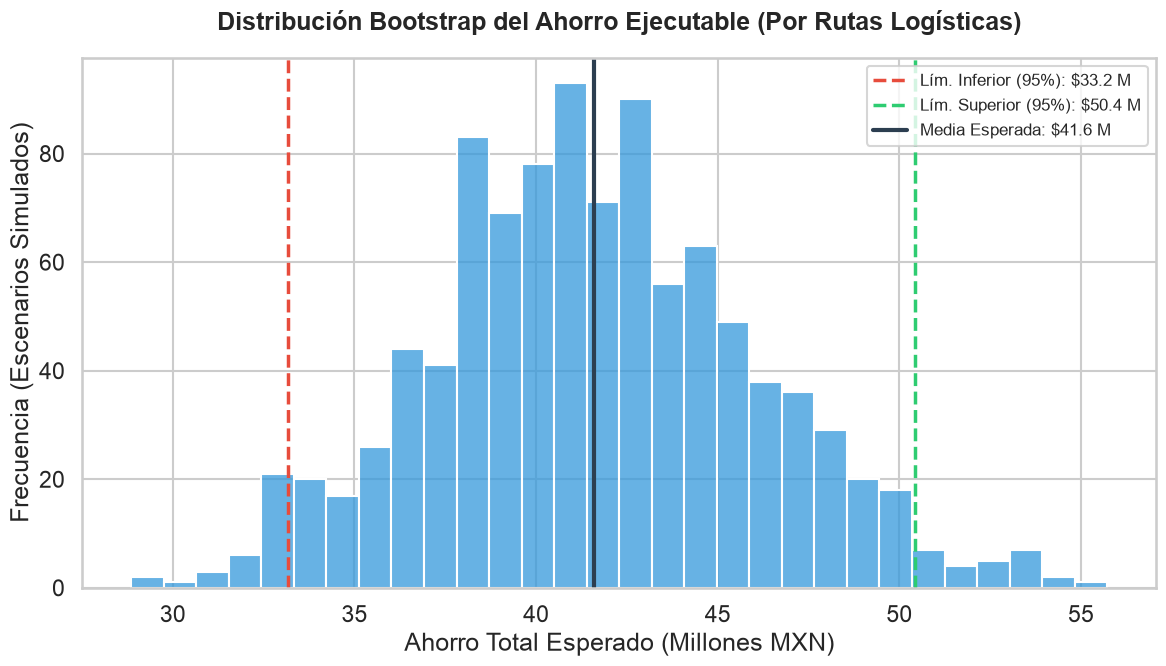

--- RESULTADOS DEL BOOTSTRAP POR CONGLOMERADOS ---
Con un 95% de confianza estadística, el modelo de Right-Sizing generará un ahorro neto anual entre:
>> $33.16 y $50.42 Millones de MXN.
>> Promedio central esperado: $41.60 Millones de MXN.


In [15]:
# Definir la función para calcular el ahorro neto por viaje
costos_medios = df.groupby(['Nomenclatura_Final', 'Categoria_Distancia'], observed=False)['Monto total'].median().to_dict()

def calcular_ahorro_viaje(row):
    original = row['Nomenclatura_Final']
    sugerido = row['Vehiculo_Recomendado_Final']
    
    if original == sugerido:
        return 0.0
        
    costo_real = row['Monto total']
    costo_esperado = costos_medios.get((sugerido, row['Categoria_Distancia']), np.inf)
    
    if costo_esperado < costo_real:
        return costo_real - costo_esperado
    return 0.0

print("Calculando el ahorro neto ejecutable fila por fila...")
df['Ahorro_Ejecutable'] = df.apply(calcular_ahorro_viaje, axis=1)

# 2. Configurar el Motor de Cluster Bootstrap (Conglomerados por Ruta Logística)
df['Ruta_ID'] = df['PLANTA_ORIGEN'] + " - " + df['Ciudad Destino']
ahorro_por_ruta = df.groupby('Ruta_ID')['Ahorro_Ejecutable'].sum()

B = 1000 # Número de simulaciones
ahorros_totales = []
rutas_unicas = df['Ruta_ID'].unique()
n_clusters = len(rutas_unicas)

print(f"Iniciando Bootstrap con {B} simulaciones (remuestreando {n_clusters} rutas)...")
np.random.seed(42) # Semilla para reproducibilidad académica

for _ in range(B):
    # Muestreo con reemplazo de las rutas
    rutas_muestra = np.random.choice(rutas_unicas, size=n_clusters, replace=True)
    rutas_counts = pd.Series(rutas_muestra).value_counts()
    
    # Sumar el ahorro del escenario simulado
    suma_iteracion = sum(ahorro_por_ruta.get(ruta, 0) * conteo for ruta, conteo in rutas_counts.items())
    ahorros_totales.append(suma_iteracion)

# 3. Calcular Métricas Estadísticas de Riesgo
ahorros_millones = np.array(ahorros_totales) / 1e6
limite_inf = np.percentile(ahorros_millones, 2.5)
limite_sup = np.percentile(ahorros_millones, 97.5)
media_boot = np.mean(ahorros_millones)

# 4. Generar la Visualización Final
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid", context="talk")
sns.histplot(ahorros_millones, bins=30, color='#3498db', edgecolor='white')

# Líneas de confianza
plt.axvline(limite_inf, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Lím. Inferior (95%): ${limite_inf:.1f} M')
plt.axvline(limite_sup, color='#2ecc71', linestyle='--', linewidth=2.5, label=f'Lím. Superior (95%): ${limite_sup:.1f} M')
plt.axvline(media_boot, color='#2c3e50', linestyle='-', linewidth=3, label=f'Media Esperada: ${media_boot:.1f} M')

plt.title('Distribución Bootstrap del Ahorro Ejecutable (Por Rutas Logísticas)', fontweight='bold', pad=20, fontsize=18)
plt.xlabel('Ahorro Total Esperado (Millones MXN)')
plt.ylabel('Frecuencia (Escenarios Simulados)')
plt.legend(frameon=True, fontsize=12)

plt.tight_layout()
plt.show()

print("--- RESULTADOS DEL BOOTSTRAP POR CONGLOMERADOS ---")
print(f"Con un 95% de confianza estadística, el modelo de Right-Sizing generará un ahorro neto anual entre:")
print(f">> ${limite_inf:.2f} y ${limite_sup:.2f} Millones de MXN.")
print(f">> Promedio central esperado: ${media_boot:.2f} Millones de MXN.")